# A first general equilibrium model

This notebook opens a series that builds a computable general equilibrium (CGE) model one block at a time. The series follows Antoine Bouet's lectures for the 2019 IFPRI / UNECA-IDEP online course "Economic Modeling applied to Trade Policy Reforms in Africa", which implements each model in GAMS. Each notebook implements the same model with `cge_modeling` and reproduces the results of the course's correction.

:::{admonition} Watch the lectures
:class: tip

- 📺 Lecture: [Computable General Equilibrium modelling: a first model](https://www.youtube.com/watch?v=hA9OuYNdgLg)
- ✅ Correction: [General Equilibrium model: first assignment and first correction](https://www.youtube.com/watch?v=0GKjRu-MIYk)
- 🎓 Full course playlist: [Antoine Bouet's CGE lectures](https://www.youtube.com/playlist?list=PLfV47vAW_jrc57x1O36Pz9vol86f0YUXW)
:::

This first model has one good, two factors and one agent. The economics are simple, so the notebook concentrates on the problem every CGE model has to solve first. A complete set of market equations does not determine the price level, and the model needs a closure before it can be solved.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from cge_modeling import CGEModel
from cge_modeling import model as cm

## The economy

A single agent owns the economy's endowments of labor and capital. A firm rents both factors and produces one good with a Cobb-Douglas technology. The agent spends all factor income on the good. There is no government, no saving or investment, and no rest of the world. Prices adjust so that the goods, labor and capital markets all clear.

A `CGEModel` collects the variables, parameters and equations declared inside a `with` block. The model below is filled in three blocks, one for each kind of object.

### Variables

The endogenous variables are the quantities produced and traded, the agent's income, and two prices. The eighth, `Leon`, is a check variable that the section on Walras's law explains.

In [2]:
mod = CGEModel()

with mod:
    Y = cm.Variable("Y", description="Production of the good")
    KD = cm.Variable("KD", description="Demand for capital")
    LD = cm.Variable("LD", description="Demand for labor")
    INC = cm.Variable("INC", description="Income of the agent")
    C = cm.Variable("C", description="Consumption of the good")
    P = cm.Variable("P", description="Price of the good")
    r = cm.Variable("r", description="Return to capital")
    Leon = cm.Variable("Leon", description="Walras check variable")

mod.summary("variables")

<IPython.core.display.Latex object>

### Parameters

The parameters are the two endowments, the two production parameters, and the wage. The wage is the numeraire and stays fixed at 1. The section on Walras's law explains why one price has to be fixed.

In [3]:
with mod:
    w = cm.Parameter("w", description="Wage, the numeraire")
    KS = cm.Parameter("KS", description="Capital supply")
    LS = cm.Parameter("LS", description="Labor supply")
    A = cm.Parameter("A", description="Total factor productivity")
    alpha = cm.Parameter("alpha", description="Output elasticity of capital")

mod.summary("parameters")

<IPython.core.display.Latex object>

### Equations

Each endogenous variable has one equation. Production is Cobb-Douglas. The two factor demands are the firm's cost-minimizing conditions, under which each factor receives a constant share of the value of output. Income is the sum of factor payments, and the agent spends all of it. The last three equations clear the goods, capital and labor markets.

In [4]:
with mod:
    cm.Equation("Production", Y, A * KD**alpha * LD ** (1 - alpha))
    cm.Equation("Capital demand", r * KD, alpha * P * Y)
    cm.Equation("Labor demand", w * LD, (1 - alpha) * P * Y)
    cm.Equation("Income", INC, w * LS + r * KS)
    cm.Equation("Consumption", P * C, INC)
    cm.Equation("Goods market clearing", Y, C)
    cm.Equation("Capital market clearing", KD, KS)
    cm.Equation("Labor market clearing", LD, LS + Leon)

mod.equation_table()

<IPython.core.display.Latex object>

In [5]:
mod.compile();

Compiling a model with 8 equations, 8 variables, 5 parameters


## Walras's law and the numeraire

Suppose the wage $w$ were a variable and equation (8) read $LD = LS$. The system would have eight equations in eight unknowns, but only seven of the equations would be independent, because equations (2) through (7) imply labor market clearing.

Start from goods market clearing (6) and split the value of output into the two factor shares:

$$P C = P Y = \alpha P Y + (1-\alpha) P Y.$$

Equation (5) turns the left side into $INC$, and equations (2) and (3) turn the right side into factor payments:

$$INC = r \, KD + w \, LD.$$

Equation (4) also defines income, as $INC = w \, LS + r \, KS$. Setting the two expressions equal and using capital market clearing (7), $KD = KS$, gives

$$r \, KS + w \, LS = r \, KS + w \, LD.$$

The capital terms cancel, and dividing by $w$ leaves $LD = LS$.

This is Walras's law (after Léon Walras): if all markets but one clear, the last one clears too. Eight equations that pin down only seven unknowns have infinitely many solutions. Doubling every price and income leaves all of them satisfied, because the equations determine relative prices and never the price level.

The course fixes the price level by choosing the wage as numeraire, $w = 1$, so every price is measured in wages. In `cge_modeling`, fixing a variable means declaring it as a parameter, which is why `w` is in the parameter block above.

Fixing $w$ leaves seven endogenous variables and eight equations. The course keeps all eight equations and adds the slack variable $Leon$ to the labor market, which gives equation (8) in the table. The other seven equations still imply $LD = LS$, so $Leon = 0$ at every solution. A nonzero value after a solve means the equations are wrong somewhere, for example a missing income flow that breaks Walras's law. Dropping one equation would also square the system, but it would give up that check.

## Data

The benchmark data are a social accounting matrix (SAM) with four accounts. Each cell is a payment from the column account to the row account. The activity pays 7000 to labor and 3000 to capital, the factors pay their income to the agent, and the agent spends 10000 on the good. Every account's row total equals its column total.

The correction program uses $LS_0 = 7000$ and $KS_0 = 3000$. The lecture's data slide lists the endowments the other way round, $KS_0 = 7000$ and $LS_0 = 3000$. This notebook follows the correction, because its numbers are the ones the results below come from.

In [6]:
accounts = ["Labor", "Capital", "Agent", "Activity"]
sam = pd.DataFrame(0.0, index=accounts, columns=accounts)
sam.loc["Labor", "Activity"] = 7000.0
sam.loc["Capital", "Activity"] = 3000.0
sam.loc["Agent", "Labor"] = 7000.0
sam.loc["Agent", "Capital"] = 3000.0
sam.loc["Activity", "Agent"] = 10_000.0

assert np.allclose(sam.sum(axis=0), sam.sum(axis=1))
sam

,Labor,Capital,Agent,Activity
Labor,0.0,0.0,0.0,7000.0
Capital,0.0,0.0,0.0,3000.0
Agent,7000.0,3000.0,0.0,0.0
Activity,0.0,0.0,10000.0,0.0


Each nonzero cell of the SAM is a payment, so the matrix can be drawn as a graph. Arrows point from the paying account (the column) to the receiving account (the row). Goods and factor services move the other way.

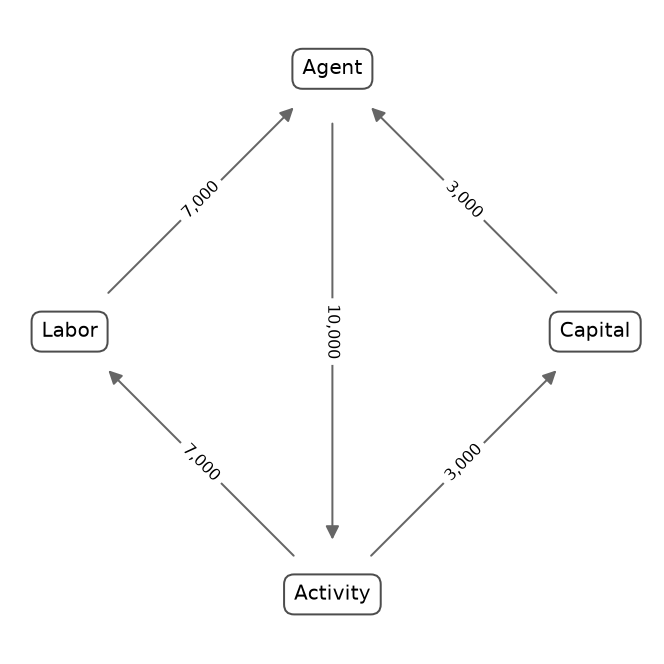

In [7]:
payment_graph = nx.from_pandas_adjacency(sam.T, create_using=nx.DiGraph)
node_positions = {"Agent": (0.0, 1.0),
                  "Labor": (-1.0, 0.0),
                  "Capital": (1.0, 0.0),
                  "Activity": (0.0, -1.0)}

fig, ax = plt.subplots(figsize=(4.5, 4.5),
                       dpi=144,
                       layout="constrained")
nx.draw_networkx_edges(payment_graph,
                       pos=node_positions,
                       ax=ax,
                       node_size=3000,
                       arrowsize=14,
                       edge_color="0.4")
nx.draw_networkx_labels(payment_graph,
                        pos=node_positions,
                        ax=ax,
                        font_size=10,
                        bbox={"boxstyle": "round,pad=0.5", "facecolor": "white", "edgecolor": "0.3"})
nx.draw_networkx_edge_labels(payment_graph,
                             pos=node_positions,
                             ax=ax,
                             edge_labels={(payer, receiver): f"{value:,.0f}"
                                          for payer, receiver, value in payment_graph.edges(data="weight")},
                             font_size=8)
ax.set_axis_off()
plt.show()

## Calibration

A SAM records only values, price times quantity. Calibration normalizes every benchmark price to 1, which chooses units so that one unit of each good or factor costs one unit of currency. Quantities are then equal to the values in the SAM, and simulation results are read as percentage changes.

The order of the calibration matters. Benchmark quantities come from the data first, then income and output, and only then the parameters $\alpha$ and $A$ that depend on them. $\alpha$ is capital's share of the value of output, from equation (2), and $A$ is the production function solved for productivity.

`mod.finalize_calibration` collects every variable and parameter from the function's local names and reports any that are missing.

In [8]:
def calibrate_model(mod, *, LS, KS):
    P = 1.0
    r = 1.0
    w = 1.0

    KD = KS
    LD = LS
    INC = w * LS + r * KS
    C = INC / P
    Y = C
    alpha = r * KD / (P * Y)
    A = Y / (KD**alpha * LD ** (1 - alpha))
    Leon = LD - LS

    return mod.finalize_calibration()


calibrated_values = calibrate_model(mod,
                                    LS=sam.loc["Labor", "Activity"],
                                    KS=sam.loc["Capital", "Activity"])
pd.Series({name: float(value) for name, value in calibrated_values.items()})

C        10000.000000
INC      10000.000000
KD        3000.000000
LD        7000.000000
Leon         0.000000
P            1.000000
Y        10000.000000
r            1.000000
A            1.842023
KS        3000.000000
LS        7000.000000
alpha        0.300000
w            1.000000
dtype: float64

A correctly calibrated model has zero residual on every equation at the benchmark, before any shock. `check_for_equilibrium` evaluates every equation at the calibrated values.

In [9]:
mod.check_for_equilibrium(calibrated_values)

Equilibrium found! Total squared error: 0.000000


## Labor supply +10%

The assignment raises labor supply by 10%. `mod.simulate` takes the calibrated equilibrium as the starting point and the shock as new parameter values. `final_delta_pct` multiplies the initial value, so 1.1 is a 10% increase.

In [10]:
labor_shock = mod.simulate(initial_state=calibrated_values,
                           final_delta_pct={"LS": 1.1})
assert labor_shock["optim_res"].success

Progress               Elapsed   Residual     ||Jᵀf||       Step         
 ───────────────────────────────────────────────────────────────────────────────────────── 
  Euler           ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00270240   33.85384474   10000/10000  
  Finding Roots   ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00000000   0.00000002        4/    4

The course reports growth rates for output, the output price and the return to capital, plus the final value of $Leon$. The function below computes the growth rates from a simulation result. The correction reports $Y = 10689.930$, $P = 1.029$ and $r = 1.100$, which are growth rates of 6.899%, 2.901% and 10.0%, and $Leon = -9.09 \times 10^{-13}$.

In [11]:
def growth_table(result, var_names):
    variables = result["optimizer"]["variables"]
    initial = variables.isel(step=0)
    final = variables.isel(step=-1)
    return pd.DataFrame({"benchmark": [float(initial[name]) for name in var_names],
                         "final": [float(final[name]) for name in var_names],
                         "growth (%)": [100 * (float(final[name]) / float(initial[name]) - 1)
                                        for name in var_names]},
                        index=var_names)


growth_table(labor_shock, var_names=["Y", "P", "r", "INC"])

,benchmark,final,growth (%)
Y,10000.0,10689.930449,6.899304
P,1.0,1.029006,2.900576
r,1.0,1.100000,10.000000
INC,10000.0,11000.000000,10.000000


In [12]:
float(labor_shock["optimizer"]["variables"]["Leon"].isel(step=-1))

1.0290142596793146e-13

The results match the correction, and $Leon$ is zero up to floating-point error, as Walras's law requires.

More labor raises output by 6.9%, less than 10%, because capital is fixed and labor has diminishing returns. Each unit of capital now works with more labor, so its marginal product rises, and with the wage fixed at 1 the return to capital rises by 10%. The output price rises by 2.9%. Prices are measured in wages, so a higher output price means a lower real wage. Because the choice of numeraire is arbitrary, the real factor prices are the results to read: $\frac{w}{P}$ falls and $\frac{r}{P}$ rises.

In [13]:
def real_factor_prices(result, w):
    final = result["optimizer"]["variables"].isel(step=-1)
    price = float(final["P"])
    return pd.Series({"w/P growth (%)": 100 * (w / price - 1),
                      "r/P growth (%)": 100 * (float(final["r"]) / price - 1)})


real_factor_prices(labor_shock, w=1.0)

w/P growth (%)   -2.818814
r/P growth (%)    6.899304
dtype: float64

### The two factor markets

Firms hire each factor until its real price equals its marginal product. With capital fixed at $KS$, the labor demand curve is

$$\frac{w}{P} = (1-\alpha) A \left(\frac{KS}{LD}\right)^{\alpha},$$

and with labor fixed at $LS$, the capital demand curve is

$$\frac{r}{P} = \alpha A \left(\frac{LS}{KD}\right)^{1-\alpha}.$$

Supply in both markets is the fixed endowment, a vertical line. More labor moves the labor supply line to the right, along a labor demand curve that does not move, so the real wage falls. In the capital market the supply line stays put, but each unit of capital now works with more labor, so the capital demand curve shifts up and the real return rises.

Moving labor supply with capital fixed slides the equilibrium along the labor demand curve, so a sweep over labor supply traces that curve from the model's own solutions. A sweep over capital supply traces the capital demand curve the same way, once with labor at its benchmark and once with labor at its shocked level. The first cell below defines the sweep with the Euler approximation, from half to double an endowment, and the second runs the three sweeps.

In [14]:
def real_outcomes(variables):
    price = np.atleast_1d(variables["P"].values)
    return pd.DataFrame({"LD": np.atleast_1d(variables["LD"].values),
                         "KD": np.atleast_1d(variables["KD"].values),
                         "Y": np.atleast_1d(variables["Y"].values),
                         "w/P": 1.0 / price,
                         "r/P": np.atleast_1d(variables["r"].values) / price})


def endowment_sweep(initial_state, parameter, low=0.5, high=2.0):
    """Return the Euler path of real outcomes as one endowment moves from low to high times its initial value."""
    paths = []
    for factor in (low, high):
        euler = mod.simulate(initial_state=initial_state,
                             final_delta_pct={parameter: factor},
                             use_optimizer=False,
                             n_iter_euler=1000,
                             progressbar=False)["euler"]
        path = real_outcomes(euler["variables"])
        path.insert(0, parameter, euler["parameters"][parameter].values)
        paths.append(path)
    return pd.concat([paths[0].iloc[::-1], paths[1]], ignore_index=True)

In [15]:
shocked_state = labor_shock["optimizer"].isel(step=-1)
shocked_values = {name: shocked_state[group][name].values
                  for group in ("variables", "parameters")
                  for name in shocked_state[group].data_vars}

labor_sweep = endowment_sweep(calibrated_values, "LS")
capital_sweep = endowment_sweep(calibrated_values, "KS")
shifted_capital_sweep = endowment_sweep(shocked_values, "KS")

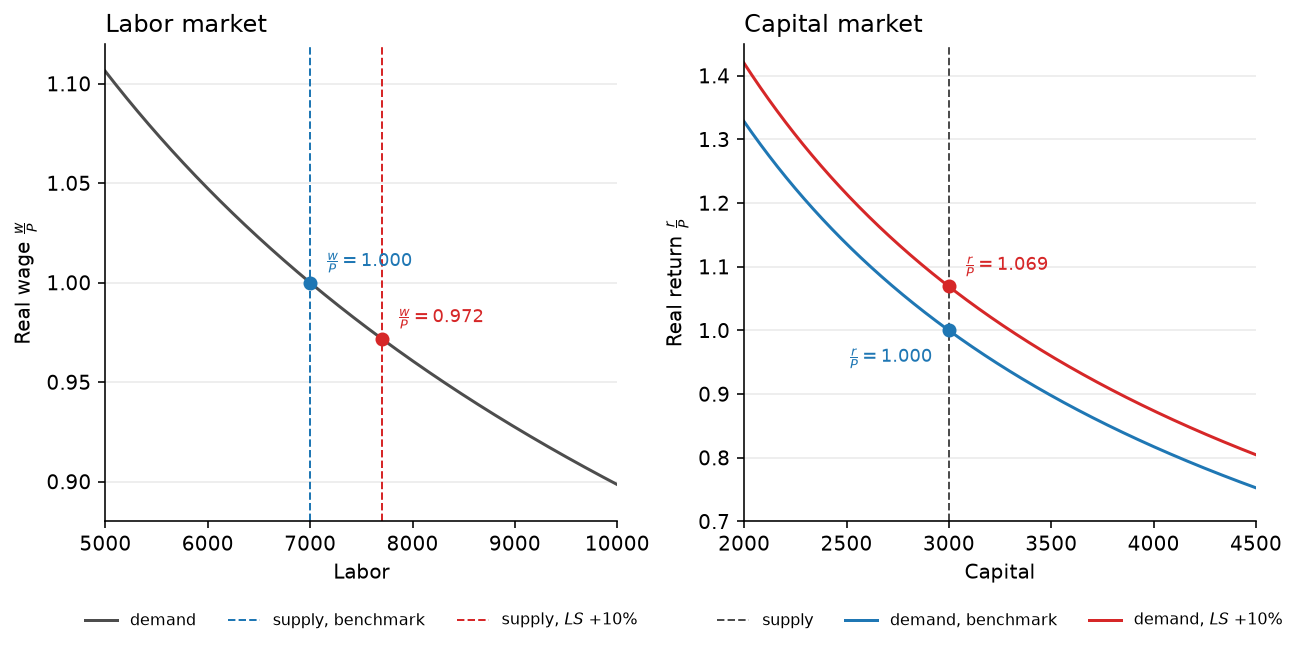

In [16]:
states = {"benchmark": real_outcomes(labor_shock["optimizer"]["variables"].isel(step=0)).iloc[0],
          "$LS$ +10%": real_outcomes(labor_shock["optimizer"]["variables"].isel(step=-1)).iloc[0]}
colors = {"benchmark": "C0", "$LS$ +10%": "C3"}
capital_demand_curves = {"benchmark": capital_sweep, "$LS$ +10%": shifted_capital_sweep}
capital_label_placements = {"benchmark": {"xytext": (-8, -16), "ha": "right"},
                            "$LS$ +10%": {"xytext": (8, 8), "ha": "left"}}

fig, (labor_ax, capital_ax) = plt.subplots(ncols=2,
                                           figsize=(9, 4.4),
                                           dpi=144,
                                           layout="constrained")
labor_ax.plot(labor_sweep["LD"],
              labor_sweep["w/P"],
              color="0.3",
              label="demand")
capital_ax.axvline(states["benchmark"]["KD"],
                   color="0.3",
                   linestyle="--",
                   linewidth=1.0,
                   label="supply")

for name, state in states.items():
    color = colors[name]

    labor_ax.axvline(state["LD"],
                     color=color,
                     linestyle="--",
                     linewidth=1.0,
                     label=f"supply, {name}")
    labor_ax.plot(state["LD"],
                  state["w/P"],
                  marker="o",
                  color=color)
    labor_ax.annotate(text=rf"$\frac{{w}}{{P}} = {state['w/P']:.3f}$",
                      xy=(state["LD"], state["w/P"]),
                      xytext=(8, 8),
                      textcoords="offset points",
                      fontsize=9,
                      color=color)

    capital_ax.plot(capital_demand_curves[name]["KD"],
                    capital_demand_curves[name]["r/P"],
                    color=color,
                    label=f"demand, {name}")
    capital_ax.plot(state["KD"],
                    state["r/P"],
                    marker="o",
                    color=color)
    capital_ax.annotate(text=rf"$\frac{{r}}{{P}} = {state['r/P']:.3f}$",
                        xy=(state["KD"], state["r/P"]),
                        textcoords="offset points",
                        fontsize=9,
                        color=color,
                        **capital_label_placements[name])

labor_ax.set(xlim=(5000.0, 10_000.0),
             ylim=(0.88, 1.12),
             xlabel="Labor",
             ylabel=r"Real wage $\frac{w}{P}$")
capital_ax.set(xlim=(2000.0, 4500.0),
               ylim=(0.7, 1.45),
               xlabel="Capital",
               ylabel=r"Real return $\frac{r}{P}$")
for ax, title in ((labor_ax, "Labor market"), (capital_ax, "Capital market")):
    ax.set_title(title,
                 loc="left")
    ax.grid(axis="y",
            color="0.92")
    ax.legend(loc="upper center",
              bbox_to_anchor=(0.5, -0.16),
              ncol=3,
              frameon=False,
              fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Capital supply +10%

The lecture's assignment also asks for a 10% increase in capital supply. The correction video describes this shock without solving it: each worker now has more capital, so the wage should rise relative to the return to capital.

In [17]:
capital_shock = mod.simulate(initial_state=calibrated_values,
                             final_delta_pct={"KS": 1.1})
assert capital_shock["optim_res"].success

Progress               Elapsed   Residual     ||Jᵀf||       Step         
 ───────────────────────────────────────────────────────────────────────────────────────── 
  Euler           ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00394111   17.87026173   10000/10000  
  Finding Roots   ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00000000   0.00000001        4/    4

In [18]:
growth_table(capital_shock, var_names=["Y", "P", "r", "INC"])

,benchmark,final,growth (%)
Y,10000.0,10290.057594,2.900576
P,1.0,0.971812,-2.818814
r,1.0,0.909091,-9.090909
INC,10000.0,10000.000000,0.000000


In [19]:
float(capital_shock["optimizer"]["variables"]["Leon"].isel(step=-1))

8.151959670476344e-13

In [20]:
real_factor_prices(capital_shock, w=1.0)

w/P growth (%)    2.900576
r/P growth (%)   -6.454022
dtype: float64

After the capital shock, output rises by 2.9%, the return to capital falls by 9.1%, and the real wage rises by 2.9%. Nominal income does not change, and $Leon$ is again zero.

Two closed-form results explain both tables. With Cobb-Douglas technology, capital income is a fixed multiple of labor income, $r \, KS = \frac{\alpha}{1-\alpha} w \, LS$, so

$$INC = w \, LS + r \, KS = \frac{w \, LS}{1-\alpha}.$$

With the wage fixed at 1, income moves one-for-one with labor supply and not at all with capital supply. Output follows the production function with both factors fully employed, and each real factor price is that factor's share of output divided by its endowment:

$$Y = A \, KS^{\alpha} LS^{1-\alpha}, \qquad \frac{w}{P} = \frac{(1-\alpha) Y}{LS}, \qquad \frac{r}{P} = \frac{\alpha Y}{KS}.$$

## Larger shocks

The plot below reuses the endowment sweeps from the factor-market section and draws output and both real factor prices along each one. To check the Euler path, the cell before it solves the model exactly with the root finder at six points on each sweep.

In [21]:
sweeps = {"LS": labor_sweep, "KS": capital_sweep}
exact_factors = [0.5, 0.75, 1.25, 1.5, 1.75, 2.0]
exact_solves = {}

for parameter in sweeps:
    solves = []
    for factor in exact_factors:
        result = mod.simulate(initial_state=calibrated_values,
                              final_delta_pct={parameter: factor},
                              n_iter_euler=100,
                              progressbar=False)
        assert result["optim_res"].success
        solve = real_outcomes(result["optimizer"]["variables"].isel(step=-1))
        solve.insert(0, parameter, factor * float(np.asarray(calibrated_values[parameter])))
        solves.append(solve)
    exact_solves[parameter] = pd.concat(solves, ignore_index=True)

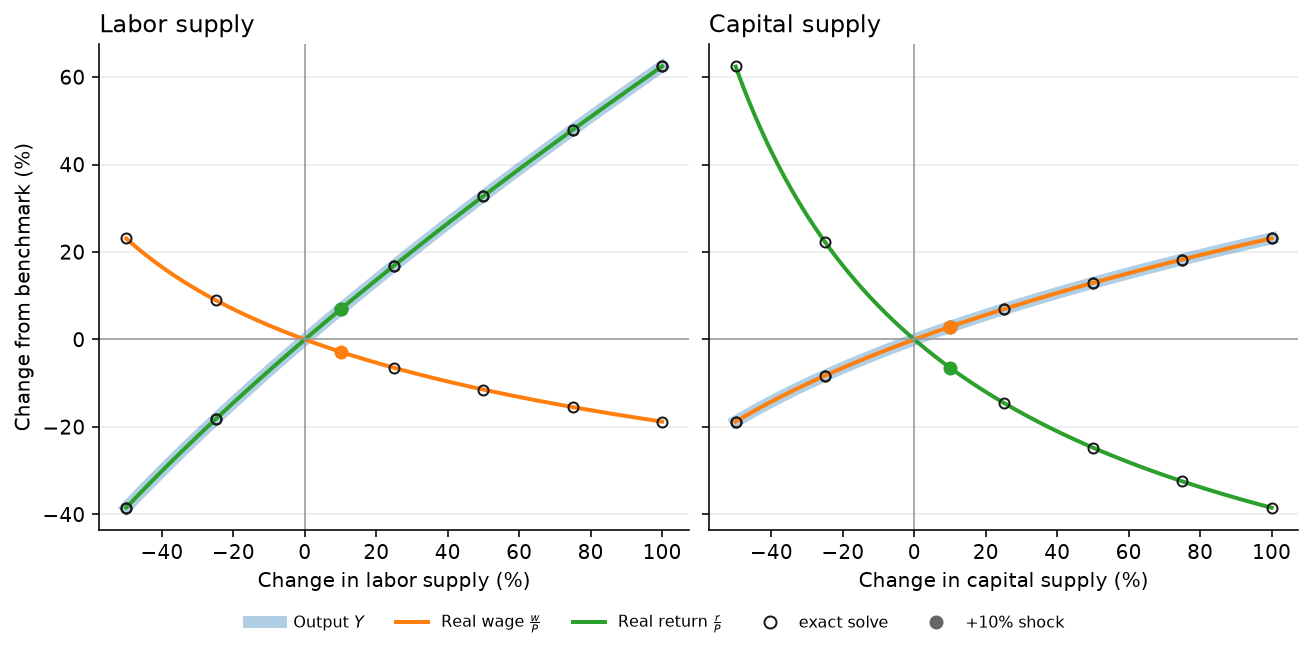

In [22]:
outcome_styles = {"Y": {"label": "Output $Y$", "color": "C0", "linewidth": 6.0, "alpha": 0.35},
                  "w/P": {"label": r"Real wage $\frac{w}{P}$", "color": "C1", "linewidth": 2.0, "alpha": 1.0},
                  "r/P": {"label": r"Real return $\frac{r}{P}$", "color": "C2", "linewidth": 2.0, "alpha": 1.0}}
benchmark_outcomes = real_outcomes(labor_shock["optimizer"]["variables"].isel(step=0)).iloc[0]
shocks = {"LS": labor_shock, "KS": capital_shock}
titles = {"LS": "Labor supply", "KS": "Capital supply"}


def pct_change(values, reference):
    return 100 * (values / reference - 1)


fig, axes = plt.subplots(ncols=2,
                         figsize=(9, 4.4),
                         dpi=144,
                         sharey=True,
                         layout="constrained")
for ax, parameter in zip(axes, ("LS", "KS")):
    benchmark_endowment = float(np.asarray(calibrated_values[parameter]))
    sweep = sweeps[parameter]
    solves = exact_solves[parameter]
    shocked = real_outcomes(shocks[parameter]["optimizer"]["variables"].isel(step=-1)).iloc[0]

    for outcome, style in outcome_styles.items():
        ax.plot(pct_change(sweep[parameter], benchmark_endowment),
                pct_change(sweep[outcome], benchmark_outcomes[outcome]),
                **style)
        ax.plot(pct_change(solves[parameter], benchmark_endowment),
                pct_change(solves[outcome], benchmark_outcomes[outcome]),
                marker="o",
                markersize=5,
                markerfacecolor="none",
                markeredgecolor="0.1",
                linestyle="none")
        ax.plot(10.0,
                pct_change(shocked[outcome], benchmark_outcomes[outcome]),
                marker="o",
                color=style["color"])

    ax.axhline(0.0,
               color="0.6",
               linewidth=0.8)
    ax.axvline(0.0,
               color="0.6",
               linewidth=0.8)
    ax.set(xlabel=f"Change in {titles[parameter].lower()} (%)")
    ax.set_title(titles[parameter],
                 loc="left")
    ax.grid(axis="y",
            color="0.92")
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Change from benchmark (%)")
axes[0].plot([],
             [],
             marker="o",
             markerfacecolor="none",
             markeredgecolor="0.1",
             linestyle="none",
             label="exact solve")
axes[0].plot([],
             [],
             color="0.4",
             marker="o",
             linestyle="none",
             label="+10% shock")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles=handles,
           labels=labels,
           loc="outside lower center",
           ncol=len(labels),
           frameon=False,
           fontsize=8)
plt.show()

The Euler paths pass through the exact solves over the whole range, and the filled dots are the two 10% shocks from above. Output changes proportionally less than either endowment, because each factor has diminishing returns. The real price of the endowment that changes moves against it.

The real price of the fixed factor moves exactly with output, because Cobb-Douglas gives each factor a constant share of output. With capital fixed, equation (2) gives $\frac{r}{P} = \frac{\alpha Y}{KS}$, and with labor fixed, equation (3) gives $\frac{w}{P} = \frac{(1-\alpha) Y}{LS}$. Each is output times a constant, so its percentage change equals output's. The output band therefore sits under the real return in the left panel and under the real wage in the right one. With a CES technology whose elasticity of substitution differs from 1, factor shares change with the factor mix and these curves would separate.

## Comparing the two shocks

Each factor gains in real terms when the other factor becomes more abundant. Output grows more after the labor shock because labor has the larger share of output, $1 - \alpha = 0.7$.

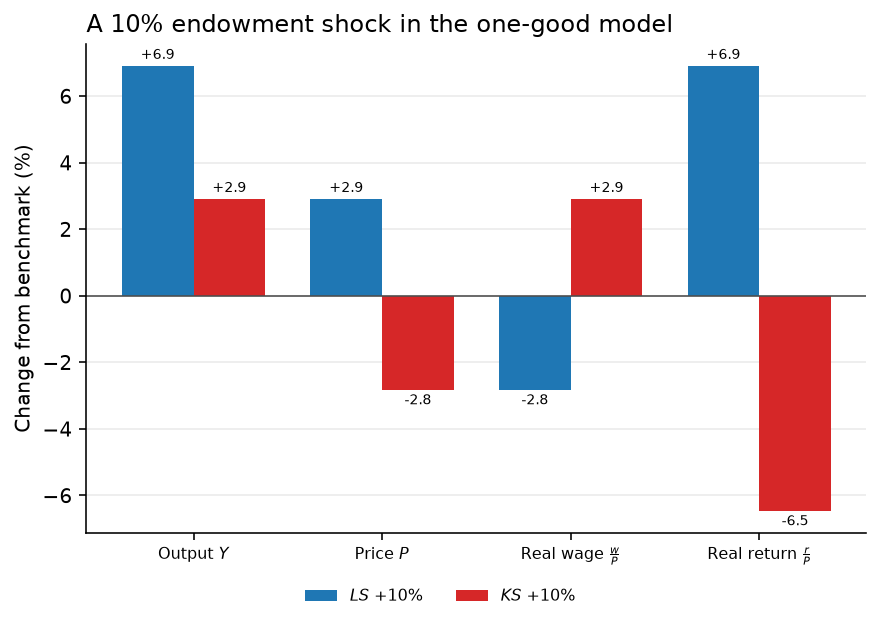

In [23]:
def shock_summary(result):
    growth = growth_table(result, var_names=["Y", "P"])["growth (%)"]
    real_prices = real_factor_prices(result, w=1.0)
    return pd.Series({"Output $Y$": growth["Y"],
                      "Price $P$": growth["P"],
                      r"Real wage $\frac{w}{P}$": real_prices["w/P growth (%)"],
                      r"Real return $\frac{r}{P}$": real_prices["r/P growth (%)"]})


summary = pd.DataFrame({"$LS$ +10%": shock_summary(labor_shock),
                        "$KS$ +10%": shock_summary(capital_shock)})

positions = np.arange(len(summary.index))
bar_width = 0.38
bar_styles = [(summary.columns[0], -bar_width / 2, "C0"),
              (summary.columns[1], bar_width / 2, "C3")]

fig, ax = plt.subplots(figsize=(6, 4.2),
                       dpi=144,
                       layout="constrained")
for column, offset, color in bar_styles:
    bars = ax.bar(positions + offset,
                  summary[column],
                  width=bar_width,
                  color=color,
                  label=column)
    ax.bar_label(bars,
                 fmt="%+.1f",
                 fontsize=7,
                 padding=2)

ax.axhline(0.0,
           color="0.3",
           linewidth=0.8)
ax.set(xticks=positions,
       ylabel="Change from benchmark (%)")
ax.set_title("A 10% endowment shock in the one-good model",
             loc="left")
ax.set_xticklabels(summary.index,
                   fontsize=8)
ax.grid(axis="y",
        color="0.92")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

handles, labels = ax.get_legend_handles_labels()
fig.legend(handles=handles,
           labels=labels,
           loc="outside lower center",
           ncol=len(labels),
           frameon=False,
           fontsize=8)
plt.show()

## Authors

- Created by Jesse Grabowski, November 25, 2026

## Watermark

In [24]:
%load_ext watermark
%watermark -n -u -v -iv -m -w

Last updated: Wed, 25 Nov 2026

Python implementation: CPython
Python version       : 3.12.13
IPython version      : 9.18.1

Compiler    : Clang 19.1.7 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit

cge_modeling: 0.0.7.dev15+g93cb61e4e.d20261120
matplotlib  : 3.11.2
networkx    : 3.6.1
numpy       : 2.3.5
pandas      : 3.1.1

Watermark: 2.6.0

